# Analytics Dashboard

This notebook visualizes the data from the Data Vault analytics layer.

In [2]:
!pip install deltalake

   ---------------------------------------- 0.0/47.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/47.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/47.9 MB 6.1 MB/s eta 0:00:08
   --- ------------------------------------ 3.7/47.9 MB 10.4 MB/s eta 0:00:05
   --- ------------------------------------ 3.7/47.9 MB 10.4 MB/s eta 0:00:05
   ---------- ----------------------------- 12.8/47.9 MB 15.8 MB/s eta 0:00:03
   -------------- ------------------------- 17.6/47.9 MB 17.3 MB/s eta 0:00:02
   ------------------ --------------------- 21.8/47.9 MB 17.6 MB/s eta 0:00:02
   --------------------- ------------------ 25.7/47.9 MB 17.9 MB/s eta 0:00:02
   ------------------------ --------------- 29.9/47.9 MB 18.1 MB/s eta 0:00:01
   ---------------------------- ----------- 34.1/47.9 MB 18.2 MB/s eta 0:00:01
   ------------------------------- -------- 38.3/47.9 MB 18.3 MB/s eta 0:00:01
   ----------------------------------- ---- 42.5/47.9 MB 18.4 MB/s eta 0:0


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import folium
import seaborn as sns
import matplotlib.pyplot as plt
import os
from deltalake import DeltaTable

# Set plotting style
sns.set_theme(style="whitegrid")

def load_delta_table(table_name):
    """Loads a Delta table into a Pandas DataFrame."""
    path = os.path.join("analytics", table_name)
    if os.path.exists(path):
        return DeltaTable(path).to_pandas()
    else:
        print(f"Table {table_name} not found.")
        return pd.DataFrame()

print("Loading Data...")
dim_well = load_delta_table("dim_well")
mart_well = load_delta_table("mart_well_performance")
mart_sensor = load_delta_table("mart_sensor_analysis")
fact_readings = load_delta_table("fact_sensor_readings")
fact_anomalies = load_delta_table("fact_anomalies")

Loading Data...


## 1. Well Map
Visualizing wells on a map with performance indicators.

In [4]:
# Center map on average location
center_lat = dim_well['location_lat'].mean()
center_long = dim_well['location_long'].mean()

m = folium.Map(location=[center_lat, center_long], zoom_start=10)

# Merge well details with performance stats
well_data = pd.merge(dim_well, mart_well, on='well_id', how='left')
well_agg = well_data.groupby(['well_id', 'well_name', 'location_lat', 'location_long', 'operator']).agg(
    total_readings=('total_readings', 'sum'),
    avg_quality=('quality_rate', 'mean')
).reset_index()

for _, row in well_agg.iterrows():
    folium.Marker(
        location=[row['location_lat'], row['location_long']],
        popup=f"Well: {row['well_name']}<br>Operator: {row['operator']}<br>Readings: {row['total_readings']}<br>Quality: {row['avg_quality']:.2f}",
        icon=folium.Icon(color='blue' if row['avg_quality'] > 0.9 else 'red', icon='tint')
    ).add_to(m)

m

## 2. Well Performance & Anomalies Overview

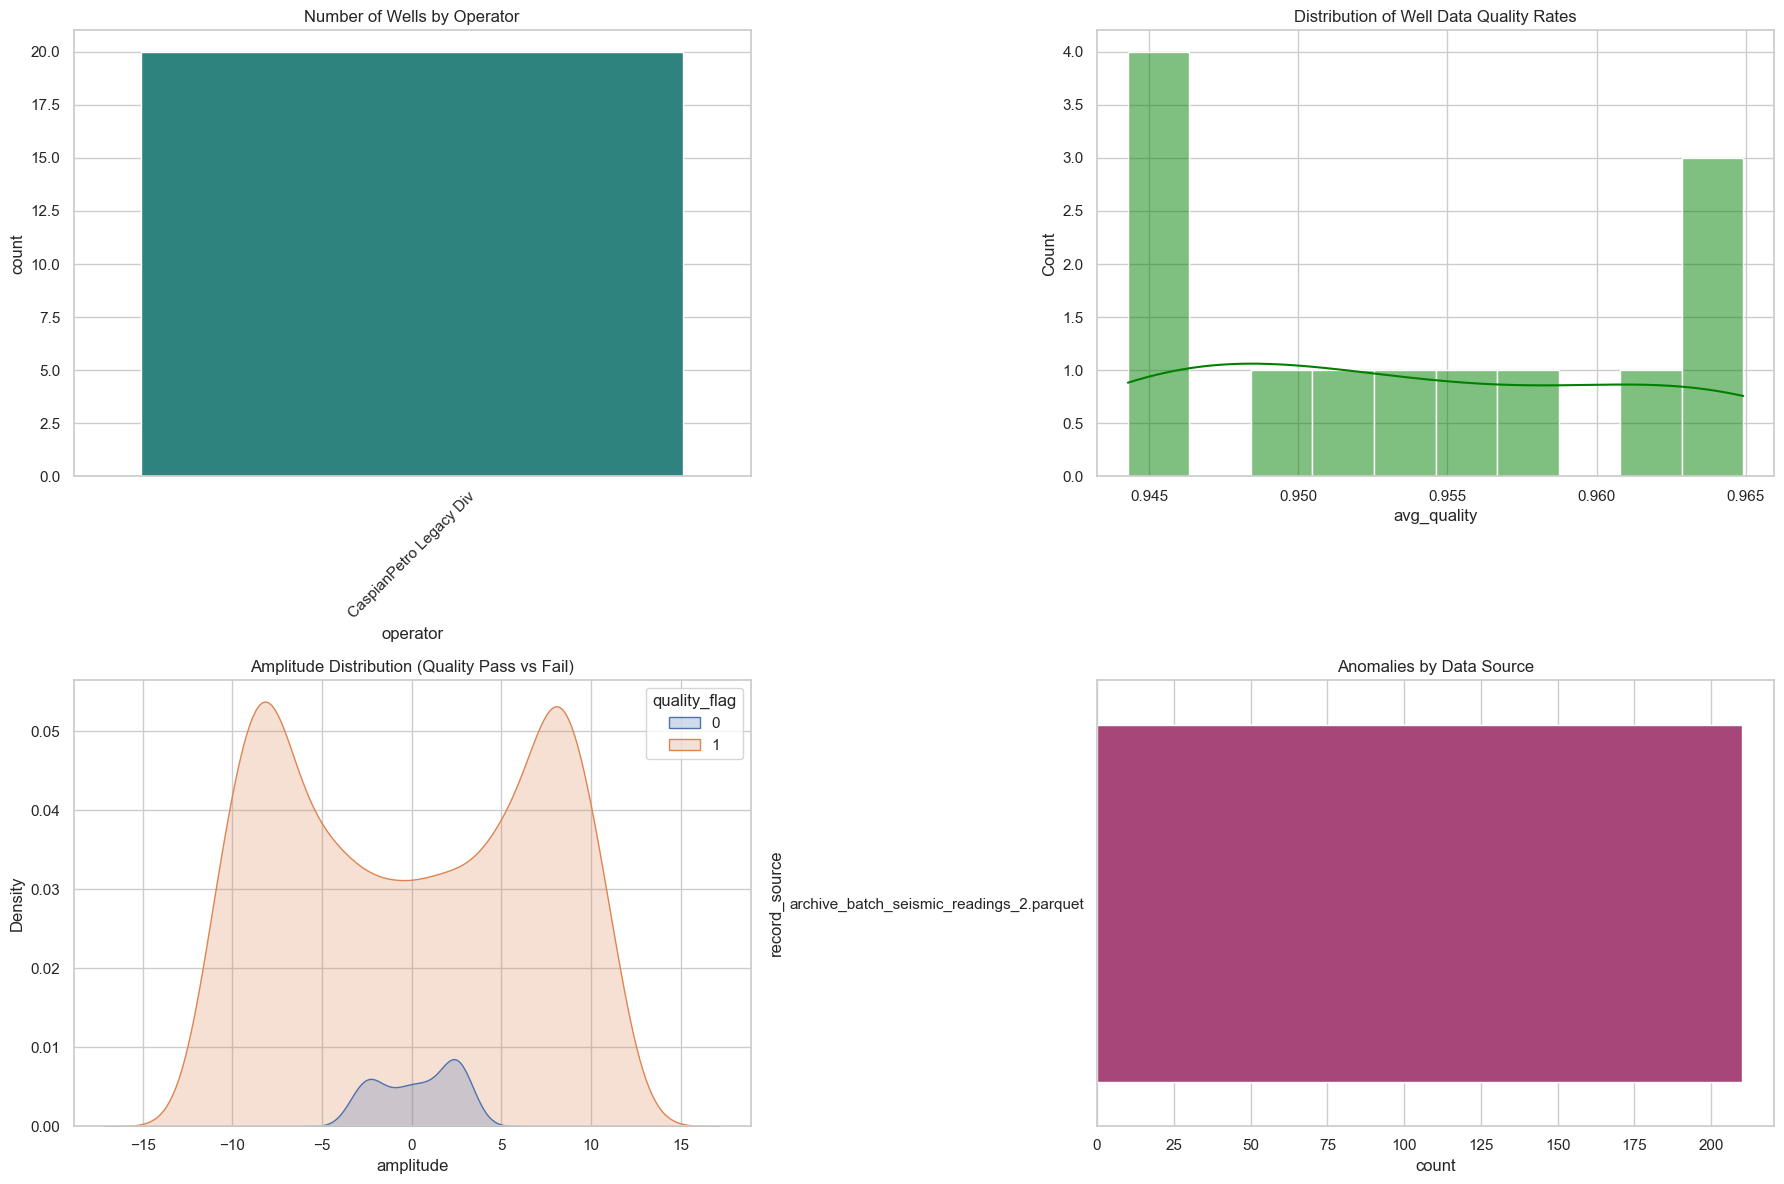

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# A. Number of Wells by Operator
sns.countplot(
    data=dim_well,
    x='operator',
    hue='operator',          # <-- əlavə olundu
    legend=False,            # <-- əlavə olundu
    ax=axes[0, 0],
    palette='viridis'
)
axes[0, 0].set_title('Number of Wells by Operator')
axes[0, 0].tick_params(axis='x', rotation=45)

# B. Data Quality Distribution (aggregated by well)
sns.histplot(well_agg['avg_quality'], bins=10, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title('Distribution of Well Data Quality Rates')

# C. Amplitude Distribution (Sampled)
sample_readings = fact_readings.sample(n=min(10000, len(fact_readings)))
sns.kdeplot(data=sample_readings, x='amplitude', hue='quality_flag', fill=True, ax=axes[1, 0])
axes[1, 0].set_title('Amplitude Distribution (Quality Pass vs Fail)')

# D. Anomaly Count by Source
if not fact_anomalies.empty:
    sns.countplot(
        data=fact_anomalies,
        y='record_source',
        hue='record_source',  # <-- əlavə olundu
        legend=False,         # <-- əlavə olundu
        ax=axes[1, 1],
        palette='magma'
    )
    axes[1, 1].set_title('Anomalies by Data Source')
else:
    axes[1, 1].text(0.5, 0.5, 'No Anomalies Found', ha='center', va='center')

plt.tight_layout()
plt.show()


## 3. Sensor Reliability

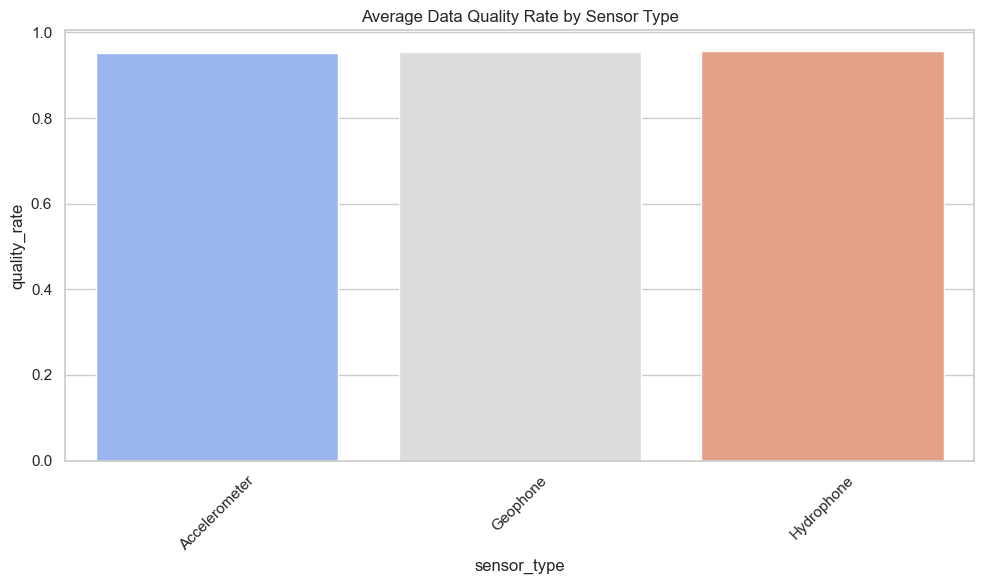

In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=mart_sensor,
    x='sensor_type',
    y='quality_rate',
    hue='sensor_type',   # <-- əlavə olundu
    legend=False,        # <-- əlavə olundu
    palette='coolwarm'
)
plt.title('Average Data Quality Rate by Sensor Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Amplitude vs Depth Heatmap

In [ ]:
plt.figure(figsize=(10, 8))
plt.hexbin(fact_readings['depth_ft'], fact_readings['amplitude'], gridsize=30, cmap='inferno', mincnt=1)
plt.colorbar(label='Count of Readings')
plt.xlabel('Depth (ft)')
plt.ylabel('Amplitude')
plt.title('Heatmap: Amplitude vs Depth')
plt.show()